<a href="https://colab.research.google.com/github/herzbay/acne-detection/blob/main/ImageDetection_SkinConditions.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import pandas as pd
import os

Import Dataset

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import tensorflow as tf
from tensorflow.keras.preprocessing import image_dataset_from_directory

dataset_dir = '/content/drive/MyDrive/kaggle/Skin_Conditions'
dataset = image_dataset_from_directory(
    dataset_dir,
    labels='inferred',
    label_mode='int',
    image_size=(224, 224),
    batch_size=32,
    shuffle=True
)

def split_dataset(dataset, train_size=0.8, val_size=0.1, test_size=0.1):
    total_size = len(dataset)
    train_end = int(total_size * train_size)
    val_end = train_end + int(total_size * val_size)

    train_dataset = dataset.take(train_end)
    val_dataset = dataset.skip(train_end).take(val_end - train_end)
    test_dataset = dataset.skip(val_end)

    return train_dataset, val_dataset, test_dataset

train_dataset, val_dataset, test_dataset = split_dataset(dataset)

Found 2403 files belonging to 6 classes.


Import Model

In [ ]:
from tensorflow.keras.models import Model
from tensorflow.keras.layers import Dense, GlobalAveragePooling2D, Dropout
from tensorflow.keras.applications import ResNet50

base_model = ResNet50(weights='imagenet', include_top=False, input_shape=(224, 224, 3))
base_model.trainable = False
x = base_model.output
x = GlobalAveragePooling2D()(x)
x = Dense(1024, activation='relu')(x)
x = Dropout(0.5)(x)
predictions = Dense(6, activation='softmax')(x)

model = Model(inputs=base_model.input, outputs=predictions)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])


94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


Augementasi Data dan Training Data

In [ ]:
from tensorflow.keras.layers import RandomFlip, RandomRotation, RandomZoom

data_augmentation = tf.keras.Sequential([
    RandomFlip("horizontal"),
    RandomRotation(0.1),
    RandomZoom(0.1)
])

def augment_data(dataset):
    def augment(image, label):
        image = data_augmentation(image)
        return image, label

    return dataset.map(augment)

train_dataset = augment_data(train_dataset)

history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5,
    batch_size=32
)

Epoch 1/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 444s 7s/step - accuracy: 0.6801 - loss: 0.9139 - val_accuracy: 0.7902 - val_loss: 0.6331
Epoch 2/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 468s 8s/step - accuracy: 0.7517 - loss: 0.6910 - val_accuracy: 0.8259 - val_loss: 0.5228
Epoch 3/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 433s 7s/step - accuracy: 0.7841 - loss: 0.6006 - val_accuracy: 0.8304 - val_loss: 0.4767
Epoch 4/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 430s 7s/step - accuracy: 0.7970 - loss: 0.5855 - val_accuracy: 0.8438 - val_loss: 0.4089
Epoch 5/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 429s 7s/step - accuracy: 0.8271 - loss: 0.4986 - val_accuracy: 0.8482 - val_loss: 0.4657


In [ ]:
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test Accuracy: {test_acc:.4f}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 56s 5s/step - accuracy: 0.8583 - loss: 0.3825
Test Accuracy: 0.8571


Fine-Tuning Model

In [ ]:
base_model.trainable = True
for layer in base_model.layers[:-20]:
    layer.trainable = False

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-5),
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

history_fine_tune = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=5,
    batch_size=32
)

Epoch 1/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 577s 9s/step - accuracy: 0.7989 - loss: 0.5923 - val_accuracy: 0.8170 - val_loss: 0.4767
Epoch 2/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 563s 9s/step - accuracy: 0.8358 - loss: 0.4758 - val_accuracy: 0.8795 - val_loss: 0.3565
Epoch 3/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 561s 9s/step - accuracy: 0.8692 - loss: 0.4223 - val_accuracy: 0.8705 - val_loss: 0.3594
Epoch 4/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 532s 9s/step - accuracy: 0.8587 - loss: 0.4268 - val_accuracy: 0.8616 - val_loss: 0.4049
Epoch 5/5
60/60 ━━━━━━━━━━━━━━━━━━━━ 529s 9s/step - accuracy: 0.8941 - loss: 0.3398 - val_accuracy: 0.8661 - val_loss: 0.3832


Evaluasi Model

In [ ]:
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test Accuracy: {test_acc:.4f}")

9/9 ━━━━━━━━━━━━━━━━━━━━ 57s 5s/step - accuracy: 0.8982 - loss: 0.2899
Test Accuracy: 0.8803


9/9 ━━━━━━━━━━━━━━━━━━━━ 59s 5s/step
Baseline Accuracy: 0.1667
Test Accuracy: 0.1892
Confusion Matrix:
[[11  8  9  7 10  7]
 [ 7  8  6  6  2 10]
 [ 8  5  8  8  7 11]
 [ 7  5  5  8  3  7]
 [10  4  5  9  5  7]
 [10  9  6  6  6  9]]
Classification Report:
              precision    recall  f1-score   support

        Acne       0.21      0.21      0.21        52
   Carcinoma       0.21      0.21      0.21        39
      Eczema       0.21      0.17      0.19        47
   Keratosis       0.18      0.23      0.20        35
       Milia       0.15      0.12      0.14        40
     Rosacea       0.18      0.20      0.19        46

    accuracy                           0.19       259
   macro avg       0.19      0.19      0.19       259
weighted avg       0.19      0.19      0.19       259



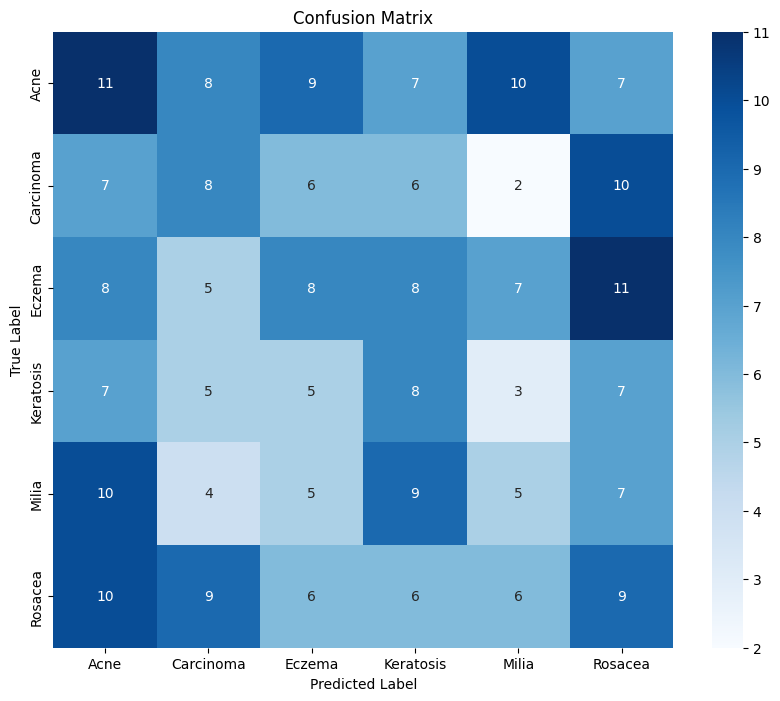

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

class_names = [
    'Acne',
    'Carcinoma',
    'Eczema',
    'Keratosis',
    'Milia',
    'Rosacea'
]

# Prediksi pada data test
y_pred = model.predict(test_dataset)
y_pred_classes = np.argmax(y_pred, axis=1)

# Dapatkan label sebenarnya dari data test
y_true = []
for images, labels in test_dataset:
  for label in labels.numpy():
    y_true.append(label)

# Akurasi Baseline
num_classes = len(class_names)
baseline_accuracy = 1 / num_classes
print(f"Baseline Accuracy: {baseline_accuracy:.4f}")

# Akurasi Model
accuracy = accuracy_score(y_true, y_pred_classes)
print(f"Test Accuracy: {accuracy:.4f}")

# Confusion Matrix
cm = confusion_matrix(y_true, y_pred_classes)
print("Confusion Matrix:")
print(cm)

# Classification Report
print("Classification Report:")
print(classification_report(y_true, y_pred_classes, target_names=class_names))

# Visualisasi Confusion Matrix
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=class_names, yticklabels=class_names)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

Analisa Grafik

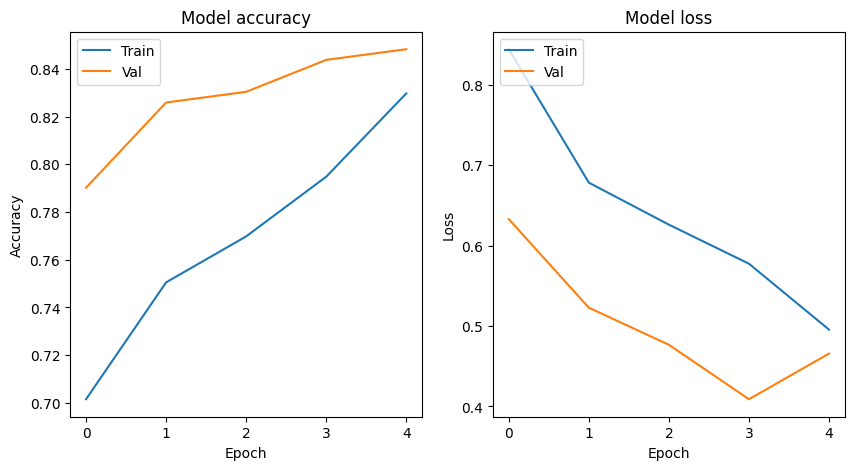

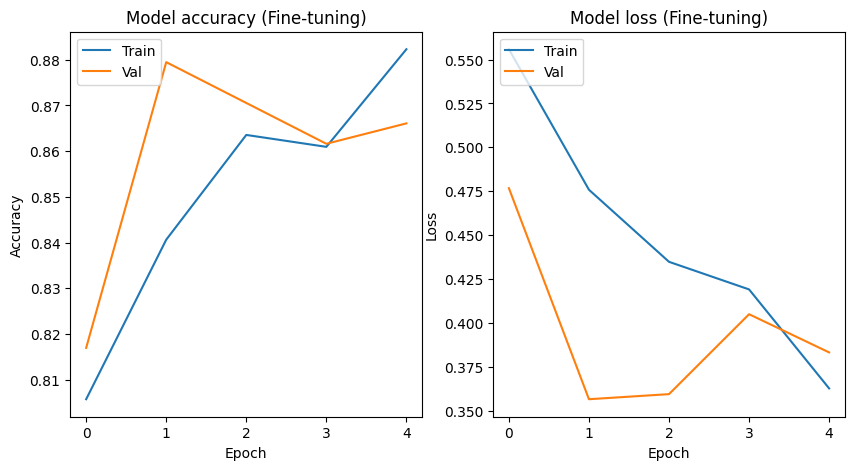

In [ ]:
import matplotlib.pyplot as plt

# Plot training & validation accuracy values
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('Model accuracy')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')

# Plot training & validation loss values
plt.subplot(1, 2, 2)
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('Model loss')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')
plt.show()

# Plot training & validation accuracy values for fine-tuning
plt.figure(figsize=(10, 5))
plt.subplot(1, 2, 1)
plt.plot(history_fine_tune.history['accuracy'])
plt.plot(history_fine_tune.history['val_accuracy'])
plt.title('Model accuracy (Fine-tuning)')
plt.ylabel('Accuracy')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')

# Plot training & validation loss values for fine-tuning
plt.subplot(1, 2, 2)
plt.plot(history_fine_tune.history['loss'])
plt.plot(history_fine_tune.history['val_loss'])
plt.title('Model loss (Fine-tuning)')
plt.ylabel('Loss')
plt.xlabel('Epoch')
plt.legend(['Train', 'Val'], loc='upper left')
plt.show()

Prediksi Pengujian Model

1/1 ━━━━━━━━━━━━━━━━━━━━ 9s 9s/step


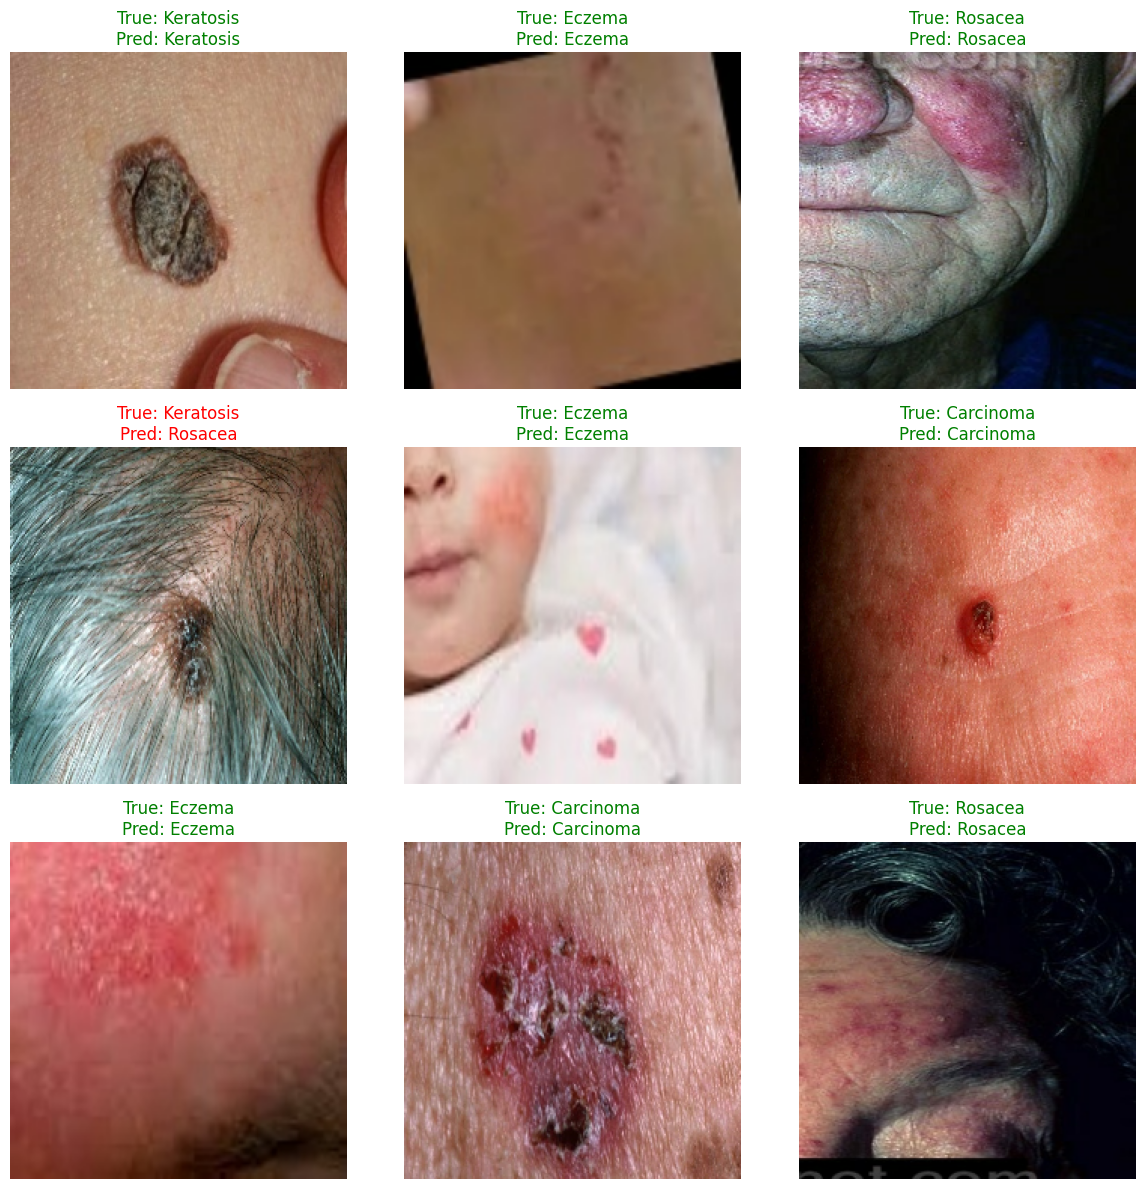

In [ ]:
import matplotlib.pyplot as plt

class_names = [
    'Acne',
    'Carcinoma',
    'Eczema',
    'Keratosis',
    'Milia',
    'Rosacea'
]

def plot_random_images(test_dataset, model, class_names, num_images=9):
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    axes = axes.flatten()

    for image_batch, label_batch in test_dataset.take(1):
        predictions = model.predict(image_batch)
        predicted_labels = np.argmax(predictions, axis=1)
        indices = np.random.choice(len(image_batch), num_images, replace=False)

        for idx, ax in enumerate(axes):
            img = image_batch[indices[idx]].numpy().astype(np.uint8)
            true_label = label_batch[indices[idx]].numpy()
            pred_label = predicted_labels[indices[idx]]

            ax.imshow(img)
            ax.axis('off')

            true_label_name = class_names[true_label]
            pred_label_name = class_names[pred_label]
            title_color = 'green' if true_label == pred_label else 'red'
            ax.set_title(f"True: {true_label_name}\nPred: {pred_label_name}", color=title_color, fontsize=12)

    plt.tight_layout()
    plt.show()

plot_random_images(test_dataset, model, class_names)